In [22]:
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

import matplotlib.pyplot as plt

In [23]:
dataset = load_diabetes(scaled=False)

In [24]:
X_raw = dataset.data
X = np.column_stack([np.ones(X_raw.shape[0]), X_raw])
y = dataset.target

In [25]:
X_, X_test, y_, y_test = train_test_split(
    X, y, test_size=0.2, random_state=67
)

X_train, X_val, y_train, y_val = train_test_split(
    X_, y_, test_size=0.2, random_state=67
)

# LSTQ

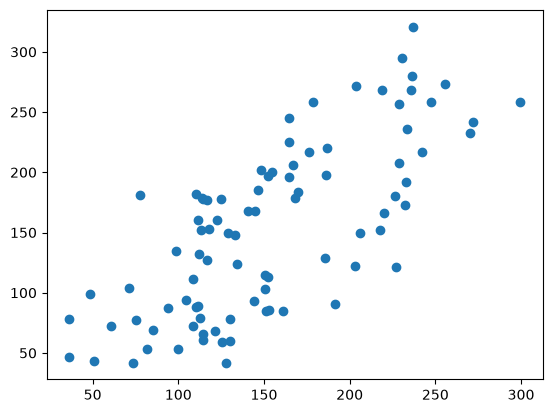

In [26]:
np.linalg.lstsq(X_train, y_train)
m, *_= np.linalg.lstsq(X_train, y_train)
plt.scatter((X_test @ m[:, None]).flatten(), y_test)

# SCIPY

In [27]:
"""
y = x.T @ b + e

distribution = lambda b, sigma: (-1/sigma**2) * np.exp(-(y_n - x_n.T @ b)**2 / (2*sigma**2))
probability_desity = p(y | X.T @ b, sigma**2) = map(mul, distribution)

minimize(probability_desity)
"""

'\ny = x.T @ b + e\n\ndistribution = lambda b, sigma: (-1/sigma**2) * np.exp(-(y_n - x_n.T @ b)**2 / (2*sigma**2))\nprobability_desity = p(y | X.T @ b, sigma**2) = map(mul, distribution)\n\nminimize(probability_desity)\n'

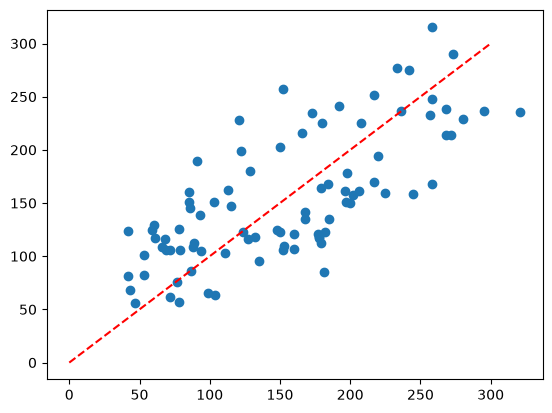

In [28]:
from sklearn.metrics import mean_squared_error
from scipy.optimize import minimize
from collections.abc import Callable, Iterable
from numpy.typing import ArrayLike
def normal_dist(X, y, b, sigma):
    return (-1/sigma**2) * np.exp(-(y - X @ b)**2 / (2*sigma**2))

def fun(X, y, b):
    return np.sum(y - X @ b)**2

def rss(beta, X, y):
    return mean_squared_error(y_true=y, y_pred=X@beta)

def rss_explicit(beta, X, y):
    n = X.shape[0]
    rss = (y - X @ beta).T @ (y - X @ beta) / n
    return rss
# result = minimize(
#     fun=rss,                       # Co minimalizujemy?
#     x0=np.zeros(X.shape[1]),      # Skąd startujemy?
#     args=(X, y),                  # Dane przekazywane do RSS
#     jac=rss_gradient,             # Jak obliczyć gradient?
#     method="BFGS",                # Jak szukać minimum?
# )

def scipy_beta(fun: Callable, x0: ArrayLike, args: Iterable, method: str="Powell"):
    minimized = minimize(
        fun=fun,
        x0=x0,
        args=args,
        method=method,
    )
    return minimized.x


beta_estimated = scipy_beta(
        fun=rss_explicit, 
        x0=np.zeros(X_train.shape[1]),
        args=(X_train, y_train),
)


plt.scatter(y_test, X_test @ beta_estimated)
plt.plot(np.linspace(0, 300), np.linspace(0, 300), 'r--')

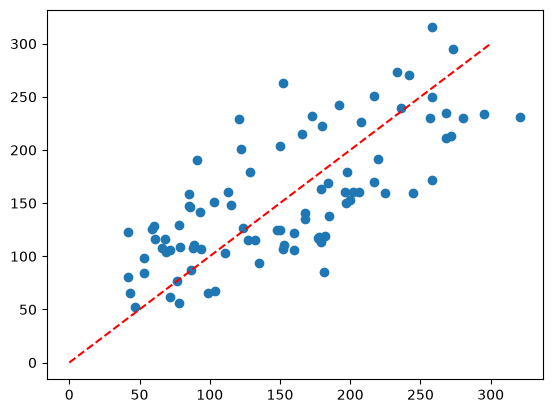

In [29]:
from scipy.stats import norm

def negative_gaussian_log_likelihood(beta, X, y, sigma):
    mu = X @ beta
    return -np.sum(norm.logpdf(y, loc=mu, scale=sigma))

beta_estimated_log_gaussian = scipy_beta(
        fun=negative_gaussian_log_likelihood, 
        x0=np.ones(X_train.shape[1]),
        args=(X_train, y_train, 1),
)

plt.scatter(y_test, X_test @ beta_estimated_log_gaussian)
plt.plot(np.linspace(0, 300), np.linspace(0, 300), 'r--')

# rige

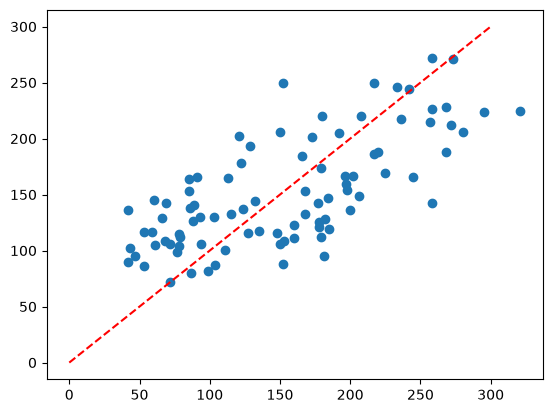

In [30]:
def rigde_loss_function(beta, X, y, lambda_):
    return mean_squared_error(y_true=y, y_pred= X @ beta) + lambda_ * np.linalg.norm(beta[1:])**2

lambda_range = np.logspace(-4, 3, 40)

ridge_scores = []
for lambda_ in lambda_range:
    beta_estimated_ridge = scipy_beta(
        fun=rigde_loss_function,
        x0=np.ones(X_train.shape[1]),
        args=(X_train, y_train, lambda_),
        method="Powell",
    )
    y_beta_estimated_ridge_pred = X_val @ beta_estimated_ridge
    current_score = np.sqrt(mean_squared_error(y_true=y_val, y_pred=y_beta_estimated_ridge_pred))
    ridge_scores.append(current_score)

best_lamda = lambda_range[np.argmin(ridge_scores)]
best_beta_estimated_ridge = scipy_beta(
        fun=rigde_loss_function,
        x0=np.ones(X_train.shape[1]),
        args=(X_train, y_train, best_lamda),
        method="Powell",
    )

plt.scatter(y_test, X_test @ best_beta_estimated_ridge)
plt.plot(np.linspace(0, 300), np.linspace(0, 300), 'r--')

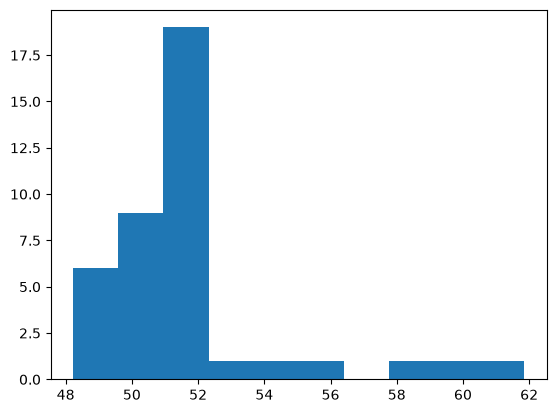

In [31]:
plt.hist(ridge_scores)
plt.show()

# lasso

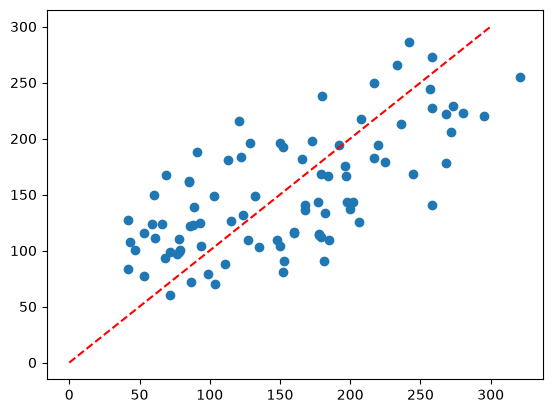

In [32]:
def lasso_loss_function(beta, X, y, lambda_):
    return mean_squared_error(y_true=y, y_pred= X @ beta) + lambda_ * np.sum(np.abs(beta[1:]))


lambda_range = np.logspace(-4, 3, 40)

lasso_scores = []
for lambda_ in lambda_range:
    beta_estimated_lasso = scipy_beta(
        fun=lasso_loss_function,
        x0=np.ones(X_train.shape[1]),
        args=(X_train, y_train, lambda_),
        method="Powell",
    )
    y_beta_estimated_lasso_pred = X_val @ beta_estimated_lasso
    current_score = np.sqrt(mean_squared_error(y_true=y_val, y_pred=y_beta_estimated_lasso_pred))
    lasso_scores.append(current_score)

best_lamda = lambda_range[np.argmin(lasso_scores)]
best_beta_estimated_lasso = scipy_beta(
        fun=lasso_loss_function,
        x0=np.ones(X_train.shape[1]),
        args=(X_train, y_train, best_lamda),
        method="Powell",
    )

plt.scatter(y_test, X_test @ best_beta_estimated_lasso)
plt.plot(np.linspace(0, 300), np.linspace(0, 300), 'r--')

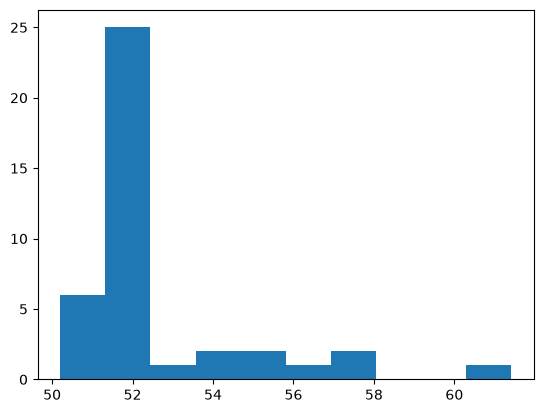

In [33]:
plt.hist(lasso_scores)
plt.show()

# proper pipeline modelling

In [34]:
import optuna
from optuna.samplers import TPESampler
from lightgbm import LGBMRegressor

from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import root_mean_squared_error
from scipy import stats

cv = KFold(n_splits=5, shuffle=True, random_state=10)


def cv_rmse(estimator):
    scores = cross_val_score(
        estimator,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1,
    )
    return -scores.mean()


def report_regression_results(model, study, label):
    print("Best parameters:", study.best_params)
    print("CV RMSE:", study.best_value)

    y_pred = model.predict(X_test)
    print(f"{label} test RMSE:", root_mean_squared_error(y_test, y_pred))

    residuals = y_test - y_pred
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    stats.probplot(residuals, dist="norm", plot=axes[0])
    axes[0].set_title("Normal Q-Q plot")

    axes[1].scatter(y_pred, residuals, alpha=0.6)
    axes[1].axhline(0, color="red", linestyle="--")
    axes[1].set_xlabel("Fitted values")
    axes[1].set_ylabel("Residuals")
    axes[1].set_title("Residuals vs fitted")

    plt.tight_layout()
    plt.show()

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    dataset.data,
    dataset.target,
    test_size=0.2,
    random_state=67,
)

[I 2026-11-01 20:12:55,080] A new study created in memory with name: no-name-3526e5dd-7c8e-490c-bb45-3972682cd1c6
[I 2026-11-01 20:12:57,631] Trial 0 finished with value: 55.86732326658215 and parameters: {'alpha': 4.245451262763637, 'fit_intercept': True}. Best is trial 0 with value: 55.86732326658215.
[I 2026-11-01 20:12:59,250] Trial 1 finished with value: 161.9249204272241 and parameters: {'alpha': 3.110450506452808, 'fit_intercept': False}. Best is trial 0 with value: 55.86732326658215.
[I 2026-11-01 20:12:59,277] Trial 2 finished with value: 161.98919008981764 and parameters: {'alpha': 0.001543040014909741, 'fit_intercept': False}. Best is trial 0 with value: 55.86732326658215.
[I 2026-11-01 20:12:59,306] Trial 3 finished with value: 55.92408120472159 and parameters: {'alpha': 0.00033887449628942543, 'fit_intercept': True}. Best is trial 0 with value: 55.86732326658215.
[I 2026-11-01 20:12:59,333] Trial 4 finished with value: 55.92410134313341 and parameters: {'alpha': 0.00010560

Best parameters: {'alpha': 10.899515085156091, 'fit_intercept': True}
CV RMSE: 55.86533989229464
Ridge test RMSE: 48.31746588691464


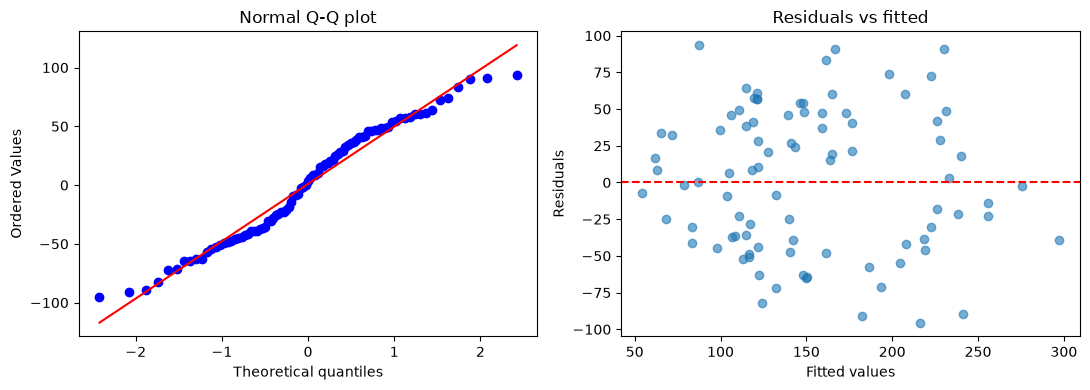

In [36]:
def ridge_objective(trial):
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("regressor", Ridge(
            alpha=trial.suggest_float("alpha", 1e-4, 1e2, log=True),
            fit_intercept=trial.suggest_categorical("fit_intercept", [False, True]),
        )),
    ])
    return cv_rmse(model)


ridge_study = optuna.create_study(
    direction="minimize",
    sampler=TPESampler(seed=10),
)
ridge_study.optimize(ridge_objective, n_trials=50)

ridge_model = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", Ridge(**ridge_study.best_params)),
])
ridge_model.fit(X_train, y_train)
report_regression_results(ridge_model, ridge_study, "Ridge")

[I 2026-11-01 20:13:00,768] A new study created in memory with name: no-name-5753512e-d7c0-492c-84d2-3c941f866fd7
[I 2026-11-01 20:13:00,797] Trial 0 finished with value: 56.43540707013972 and parameters: {'alpha': 4.245451262763637}. Best is trial 0 with value: 56.43540707013972.
[I 2026-11-01 20:13:00,823] Trial 1 finished with value: 55.92402774760982 and parameters: {'alpha': 0.0001332022915065908}. Best is trial 1 with value: 55.92402774760982.
[I 2026-11-01 20:13:00,848] Trial 2 finished with value: 55.8265506753389 and parameters: {'alpha': 0.6337083207484672}. Best is trial 2 with value: 55.8265506753389.
[I 2026-11-01 20:13:00,863] Trial 3 finished with value: 56.06836823302418 and parameters: {'alpha': 3.110450506452808}. Best is trial 2 with value: 55.8265506753389.
[I 2026-11-01 20:13:00,878] Trial 4 finished with value: 55.880381527570265 and parameters: {'alpha': 0.09795848815655205}. Best is trial 2 with value: 55.8265506753389.
[I 2026-11-01 20:13:00,894] Trial 5 finish

Best parameters: {'alpha': 1.4193564997445134}
CV RMSE: 55.80805764590688
Lasso test RMSE: 48.4752655367318


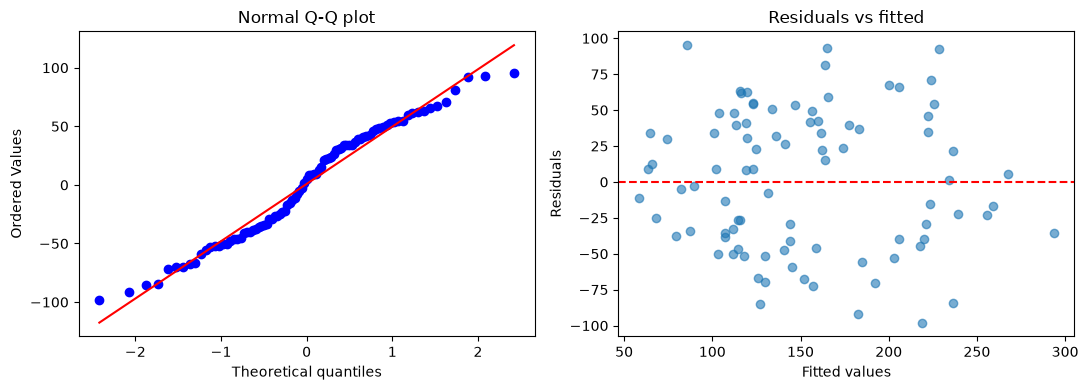

In [37]:
def lasso_objective(trial):
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("regressor", Lasso(
            alpha=trial.suggest_float("alpha", 1e-4, 1e2, log=True),
            max_iter=10000,
        )),
    ])
    return cv_rmse(model)


lasso_study = optuna.create_study(
    direction="minimize",
    sampler=TPESampler(seed=10),
)
lasso_study.optimize(lasso_objective, n_trials=50)

lasso_model = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", Lasso(**lasso_study.best_params, max_iter=10000)),
])
lasso_model.fit(X_train, y_train)
report_regression_results(lasso_model, lasso_study, "Lasso")

[I 2026-11-01 20:13:02,117] A new study created in memory with name: no-name-8296e268-4cb6-4d0c-8686-ff5f19b698f4
[I 2026-11-01 20:13:02,146] Trial 0 finished with value: 65.51288368969391 and parameters: {'alpha': 4.245451262763637, 'l1_ratio': 0.11867675442346136}. Best is trial 0 with value: 65.51288368969391.
[I 2026-11-01 20:13:02,163] Trial 1 finished with value: 55.979337814864984 and parameters: {'alpha': 0.6337083207484672, 'l1_ratio': 0.7739234942847507}. Best is trial 1 with value: 55.979337814864984.
[I 2026-11-01 20:13:02,179] Trial 2 finished with value: 55.870533878571145 and parameters: {'alpha': 0.09795848815655205, 'l1_ratio': 0.30231698097776294}. Best is trial 2 with value: 55.870533878571145.
[I 2026-11-01 20:13:02,205] Trial 3 finished with value: 55.91599467106922 and parameters: {'alpha': 0.001543040014909741, 'l1_ratio': 0.7844776409790628}. Best is trial 2 with value: 55.870533878571145.
[I 2026-11-01 20:13:02,231] Trial 4 finished with value: 55.9070427418810

Best parameters: {'alpha': 0.2596569917898026, 'l1_ratio': 0.8925508244935654}
CV RMSE: 55.83816340151134
ElasticNet test RMSE: 48.30697657067489


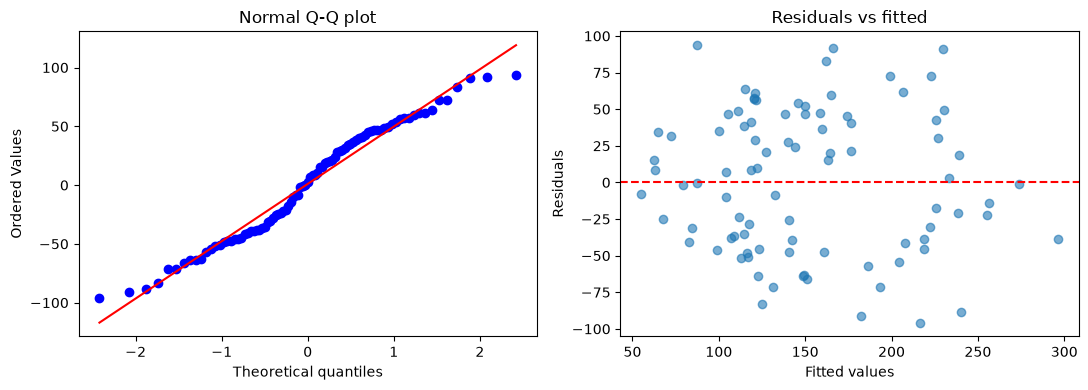

In [38]:
def elastic_net_objective(trial):
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("regressor", ElasticNet(
            alpha=trial.suggest_float("alpha", 1e-4, 1e2, log=True),
            l1_ratio=trial.suggest_float("l1_ratio", 0.1, 1.0),
            max_iter=10000,
        )),
    ])
    return cv_rmse(model)


elastic_net_study = optuna.create_study(
    direction="minimize",
    sampler=TPESampler(seed=10),
)
elastic_net_study.optimize(elastic_net_objective, n_trials=50)

elastic_net_model = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", ElasticNet(**elastic_net_study.best_params, max_iter=10000)),
])
elastic_net_model.fit(X_train, y_train)
report_regression_results(elastic_net_model, elastic_net_study, "ElasticNet")

OLS CV RMSE: 55.924110462985865
Test RMSE: 48.03793441202272


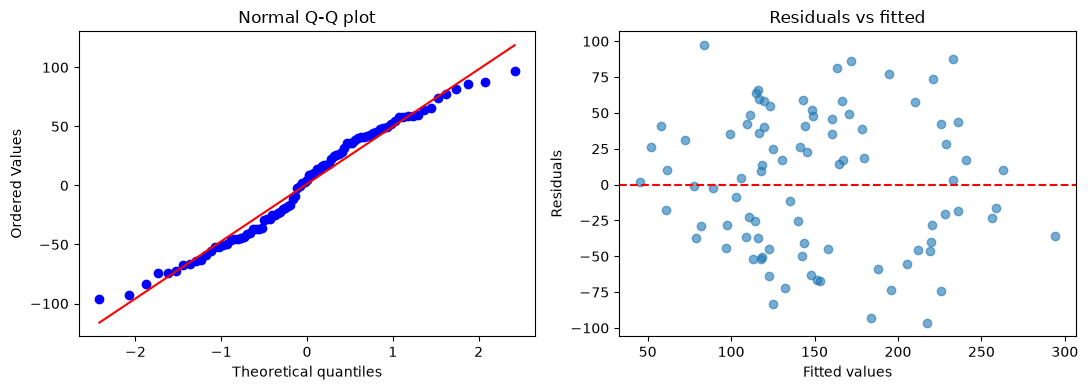

In [39]:
linreg_pipeline = Pipeline(
    [
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression(fit_intercept=True)),
    ]
)

ols_cv = cross_val_score(
    estimator=linreg_pipeline,
    X=X_train,
    y=y_train,
    cv=KFold(n_splits=5, shuffle=True, random_state=10),
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)

linreg_pipeline.fit(X_train, y_train)

y_pred = linreg_pipeline.predict(X_test)
print("OLS CV RMSE:", -ols_cv.mean())
print("Test RMSE:", root_mean_squared_error(y_test, y_pred))

residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

stats.probplot(residuals, dist="norm", plot=axes[0])
axes[0].set_title("Normal Q-Q plot")

axes[1].scatter(y_pred, residuals, alpha=0.6)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("Fitted values")
axes[1].set_ylabel("Residuals")
axes[1].set_title("Residuals vs fitted")

plt.tight_layout()
plt.show()

[I 2026-11-01 20:13:03,861] A new study created in memory with name: no-name-c39a85d8-5453-456d-b88a-70585abf0099
[I 2026-11-01 20:13:04,873] Trial 0 finished with value: 57.763669620459346 and parameters: {'n_estimators': 400, 'max_depth': 20, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 0.8426799091838986}. Best is trial 0 with value: 57.763669620459346.
[I 2026-11-01 20:13:05,809] Trial 1 finished with value: 57.57633919814755 and parameters: {'n_estimators': 500, 'max_depth': 20, 'min_samples_split': 15, 'min_samples_leaf': 6, 'max_features': 0.5710850238007634}. Best is trial 1 with value: 57.57633919814755.
[I 2026-11-01 20:13:06,159] Trial 2 finished with value: 56.75690324286673 and parameters: {'n_estimators': 200, 'max_depth': None, 'min_samples_split': 17, 'min_samples_leaf': 6, 'max_features': 0.9543244404043341}. Best is trial 2 with value: 56.75690324286673.
[I 2026-11-01 20:13:06,541] Trial 3 finished with value: 56.87308782181439 and parameters: {'n_es

Best parameters: {'n_estimators': 450, 'max_depth': None, 'min_samples_split': 17, 'min_samples_leaf': 1, 'max_features': 0.781957281882376}
CV RMSE: 56.485174452125634
ExtraTrees test RMSE: 49.19256456063234


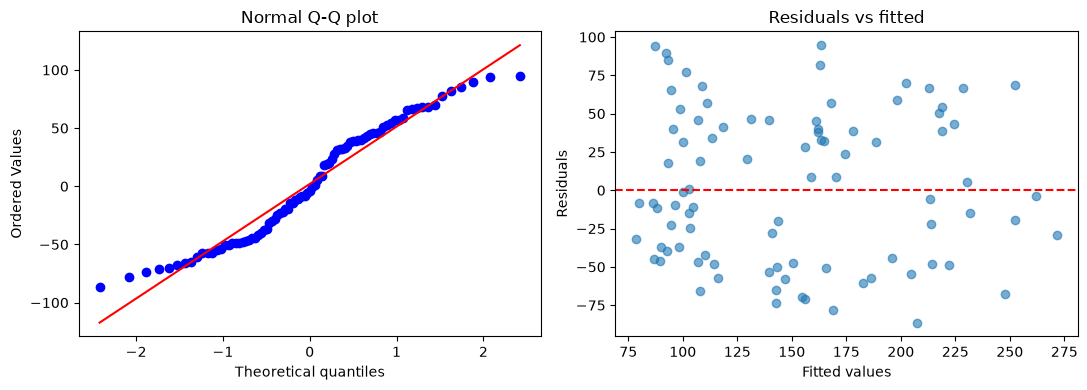

In [40]:
def extra_trees_objective(trial):
    model = ExtraTreesRegressor(
        n_estimators=trial.suggest_int("n_estimators", 50, 500, step=50),
        max_depth=trial.suggest_categorical(
            "max_depth", [None, 3, 5, 8, 12, 16, 20]
        ),
        min_samples_split=trial.suggest_int("min_samples_split", 2, 20),
        min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 10),
        max_features=trial.suggest_float("max_features", 0.5, 1.0),
        random_state=10,
    )
    return cv_rmse(model)


extra_trees_study = optuna.create_study(
    direction="minimize",
    sampler=TPESampler(seed=10),
)
extra_trees_study.optimize(extra_trees_objective, n_trials=50)

extra_trees_model = ExtraTreesRegressor(
    **extra_trees_study.best_params,
    random_state=10,
)
extra_trees_model.fit(X_train, y_train)
report_regression_results(extra_trees_model, extra_trees_study, "ExtraTrees")

## LightGBM Regressor with Optuna

[I 2026-11-01 20:13:40,688] A new study created in memory with name: no-name-c26052bc-9396-4c63-9344-4fcf937dc5b3
[I 2026-11-01 20:13:40,912] Trial 0 finished with value: 59.664408814625304 and parameters: {'n_estimators': 794, 'learning_rate': 0.010641403439556926, 'num_leaves': 44, 'max_depth': 10, 'min_child_samples': 22, 'subsample': 0.6899186582123391, 'colsample_bytree': 0.6792251459038496, 'reg_alpha': 0.0699481785242808, 'reg_lambda': 3.32657660618516e-07}. Best is trial 0 with value: 59.664408814625304.
[I 2026-11-01 20:13:40,991] Trial 1 finished with value: 61.61887143482827 and parameters: {'n_estimators': 179, 'learning_rate': 0.07792443849178458, 'num_leaves': 62, 'max_depth': 3, 'min_child_samples': 23, 'subsample': 0.9250483846608454, 'colsample_bytree': 0.8450104267317553, 'reg_alpha': 0.03131827670437561, 'reg_lambda': 4.235304245072407e-06}. Best is trial 0 with value: 59.664408814625304.
[I 2026-11-01 20:13:41,210] Trial 2 finished with value: 68.09883189956804 and 

Best parameters: {'n_estimators': 235, 'learning_rate': 0.012523705040944782, 'num_leaves': 57, 'max_depth': 3, 'min_child_samples': 18, 'subsample': 0.6246660040528647, 'colsample_bytree': 0.9533879163576264, 'reg_alpha': 2.531195848897926e-07, 'reg_lambda': 0.00037856044768981605}
CV RMSE: 57.34692191076734
LightGBM test RMSE: 50.0673225751204


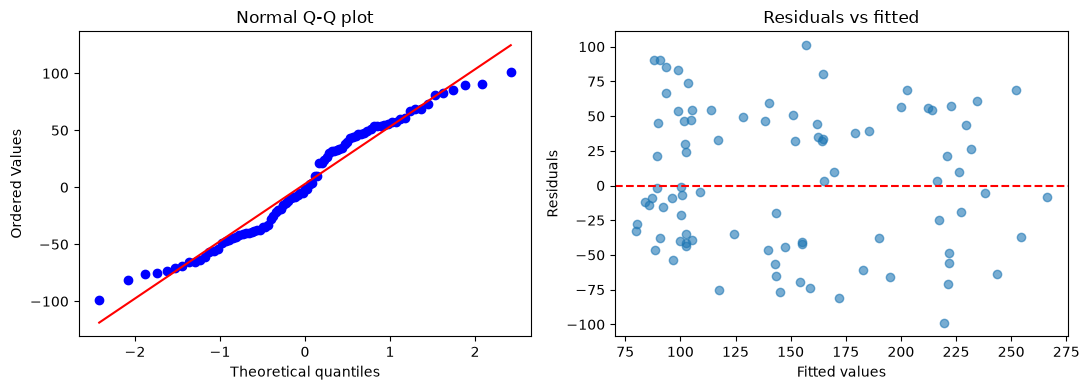

In [41]:
def lgbm_objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 1000),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 8, 64),
        "max_depth": trial.suggest_int("max_depth", 3, 12),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 40),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-8, 10.0, log=True),
    }
    model = LGBMRegressor(
        **params,
        subsample_freq=1,
        random_state=10,
        n_jobs=1,
        verbosity=-1,
    )
    return cv_rmse(model)


lgbm_study = optuna.create_study(
    direction="minimize",
    sampler=TPESampler(seed=10),
)
lgbm_study.optimize(lgbm_objective, n_trials=50)

lgbm_model = LGBMRegressor(
    **lgbm_study.best_params,
    subsample_freq=1,
    random_state=10,
    n_jobs=1,
    verbosity=-1,
)
lgbm_model.fit(X_train, y_train)
report_regression_results(lgbm_model, lgbm_study, "LightGBM")